<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Explanation of the PPCA Generative Model

Probabilistic Principal Component Analysis (PPCA) is a probabilistic formulation of standard PCA based on a latent variable model. It models the observed high-dimensional data vector $\mathbf{x} \in \mathbb{R}^d$ as a linear mapping of a lower-dimensional latent variable $\mathbf{z} \in \mathbb{R}^q$ (where $q < d$) plus some additive noise.

The generative model is defined as:
$$\mathbf{x} = \mathbf{W}\mathbf{z} + \boldsymbol{\mu} + \boldsymbol{\varepsilon}$$

Where:
- $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_q)$ is the $q$-dimensional latent state (principal components).
- $\mathbf{W} \in \mathbb{R}^{d \times q}$ is the factor loading matrix (relating the latent space to the data space).
- $\boldsymbol{\mu} \in \mathbb{R}^d$ is the mean vector of the data.
- $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I}_d)$ is isotropic Gaussian noise representing sensor noise, where $\sigma^2$ is the noise variance.

Under this model, the observed data $\mathbf{x}$ follows a marginal distribution:
$$\mathbf{x} \sim \mathcal{N}(\boldsymbol{\mu}, \mathbf{W}\mathbf{W}^T + \sigma^2 \mathbf{I}_d)$$

Unlike standard PCA, PPCA defines a proper probability density, allowing us to compute likelihoods, handle missing values naturally, and generate new synthetic samples using the model parameters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate clean synthetic multivariate sensor data (e.g., 5 sensors)
n_samples = 500
n_features = 5
latent_dim = 2

# True underlying latent structure (e.g., 2 independent physical states driving 5 sensors)
Z_true = np.random.normal(size=(n_samples, latent_dim))
W_true = np.array([
    [0.8,  0.1],
    [-0.5, 0.7],
    [0.9,  0.4],
    [0.1, -0.8],
    [0.6,  0.6]
])
mean_true = np.array([10.0, 50.0, 0.5, 120.0, 5.0])

# Clean data
X_clean = np.dot(Z_true, W_true.T) + mean_true

# Add isotropic Gaussian noise (sigma^2 = 0.25 => sigma = 0.5)
true_sigma2 = 0.25
noise = np.random.normal(scale=np.sqrt(true_sigma2), size=X_clean.shape)
X_noisy = X_clean + noise

print(f"Generated {n_samples} samples with {n_features} features.")
print(f"Assigned ground truth noise variance (sigma^2): {true_sigma2}")

Generated 500 samples with 5 features.
Assigned ground truth noise variance (sigma^2): 0.25


### Task 2 & 3: Fit PPCA and Estimate Noise Variance ($\sigma^2$)

In Scikit-learn, the `PCA` class implements Probabilistic PCA when we instantiate it (it automatically estimates the noise variance $\sigma^2$ via maximum likelihood when the number of components $q$ is strictly less than the data dimension $d$).

In [2]:
# Fit PPCA with q = 2 components
q = 2
ppca = PCA(n_components=q)
ppca.fit(X_noisy)

# Estimate noise variance (sigma^2)
estimated_noise_variance = ppca.noise_variance_

print(f"Number of components: {q}")
print(f"Estimated noise variance (sigma^2): {estimated_noise_variance:.4f}")
print(f"Ground truth noise variance: {true_sigma2:.4f}")

Number of components: 2
Estimated noise variance (sigma^2): 0.2422
Ground truth noise variance: 0.2500


### Task 4: Reconstruction Analysis against Component Count

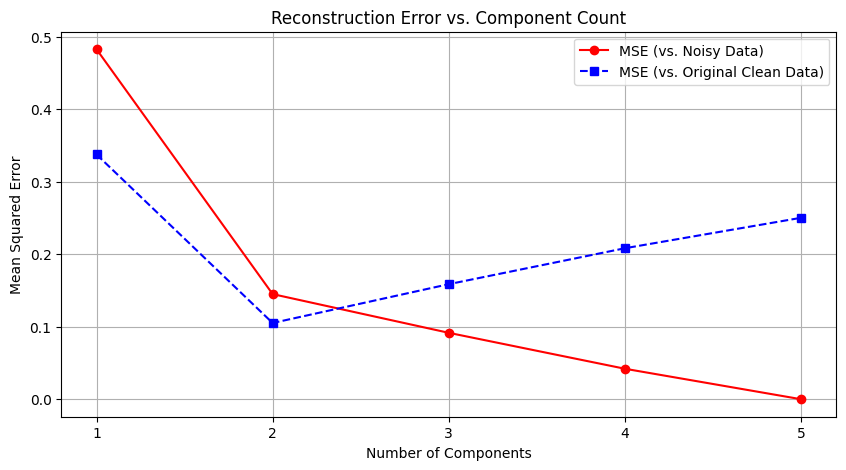

In [3]:
# We will compare PPCA (using inverse_transform) and standard Reconstruction Errors
components_range = range(1, n_features + 1)
reconstruction_errors_noisy = []
reconstruction_errors_clean = [] # Ground truth clean target evaluation

for c in components_range:
    pca_model = PCA(n_components=c)
    X_transformed = pca_model.fit_transform(X_noisy)
    X_reconstructed = pca_model.inverse_transform(X_transformed)

    # MSE against the noisy input
    mse_noisy = np.mean((X_noisy - X_reconstructed) ** 2)
    reconstruction_errors_noisy.append(mse_noisy)

    # MSE against the original clean data (to see how well noise is filtered)
    mse_clean = np.mean((X_clean - X_reconstructed) ** 2)
    reconstruction_errors_clean.append(mse_clean)

# Plot the results
plt.figure(figsize=(10, 5))
plt.plot(components_range, reconstruction_errors_noisy, 'o-', label='MSE (vs. Noisy Data)', color='red')
plt.plot(components_range, reconstruction_errors_clean, 's--', label='MSE (vs. Original Clean Data)', color='blue')
plt.xlabel('Number of Components')
plt.ylabel('Mean Squared Error')
plt.title('Reconstruction Error vs. Component Count')
plt.xticks(components_range)
plt.grid(True)
plt.legend()
plt.show()

### Task 5: Generate New Synthetic Sensor Samples from the Fitted Model

We generate new samples by drawing $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_q)$ and noise $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 \mathbf{I}_d)$, then computing $\mathbf{x} = \mathbf{W}\mathbf{z} + \boldsymbol{\mu} + \boldsymbol{\varepsilon}$.

In [4]:
# Number of synthetic samples to generate
n_new_samples = 5

# Extract fitted parameters
W_fitted = ppca.components_.T * np.sqrt(ppca.explained_variance_[:, np.newaxis]).T # Adjusting directions by singular values scale
mean_fitted = ppca.mean_
sigma2_fitted = ppca.noise_variance_

# Alternatively, we can project random latent samples back using inverse_transform
# generate latent vectors z ~ N(0, I)
z_new = np.random.normal(size=(n_new_samples, q))

# Reconstruct back to data space: x_clean_syn = z_new * W^T + mu
X_syn_clean = ppca.inverse_transform(z_new)

# Add the modeled isotropic noise: epsilon ~ N(0, sigma^2 * I)
synthetic_noise = np.random.normal(scale=np.sqrt(sigma2_fitted), size=X_syn_clean.shape)
X_synthetic = X_syn_clean + synthetic_noise

print(f"Generated {n_new_samples} new synthetic sensor readings:")
import pandas as pd
df_synthetic = pd.DataFrame(X_synthetic, columns=[f"Sensor_{i+1}" for i in range(n_features)])
display(df_synthetic)

Generated 5 new synthetic sensor readings:


,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5
0,11.375136,49.164672,2.186440,119.188101,5.872714
1,10.265228,49.664561,0.737214,120.572986,4.011002
2,10.499832,47.817208,-0.080811,121.736545,4.313250
3,9.617456,49.884077,1.737638,119.035406,4.728008
4,11.169518,50.565671,0.850527,119.561743,6.314791
